# ECM gene program in ccRCC — analysis notebook

This notebook walks through the whole analysis in order and shows the numbers and figures the
report is built from. Heavy computation lives in the `opengo` package and its CLI
(`uv run opengo all` regenerates everything from the supplied inputs, ≈ 45 min, peak ≈ 3 GB);
this notebook reads the resulting tables and figures, so it runs in seconds from a clean session.

Every decision, with its evidence and the alternatives considered, is in
`outputs/tables/decisions_log.tsv`; the reasoning per stage is in `README.md`.

In [1]:
import io
from pathlib import Path

import pandas as pd
from PIL import Image as PILImage
from IPython.display import Image, Markdown, display

from opengo import config

T = config.TABLES_DIR
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)


def show(path: Path, width: int = 1000) -> None:
    """Embed a downscaled copy (keeps the notebook small); full-size files are in outputs/."""
    img = PILImage.open(path)
    img.thumbnail((width * 1.5, 10_000))
    buf = io.BytesIO()
    img.convert("RGB").save(buf, format="JPEG", quality=82)
    display(Image(data=buf.getvalue(), width=width))


def table(name: str) -> pd.DataFrame:
    return pd.read_csv(T / f"{name}.tsv", sep="\t")

## 0 · Inputs and environment
All 70 supplied files are checked against `FILE_MANIFEST.tsv` (size + SHA-256).

In [2]:
table("input_verification")["status"].value_counts()

status
ok    70
Name: count, dtype: int64

## 1 · Loading and reconciliation
Cohort A raw droplet matrices are restricted to the author-annotated nuclei; B and C are loaded
in full. Cells per cohort must equal the documentation (141,950 / 157,881 / 29,499).

In [3]:
spec = table("stage1_specimens")
spec.groupby("cohort").agg(
    specimens=("sample_id", "size"),
    cells=("cells_loaded", "sum"),
    annotations_matched=("annotated_matched", "sum"),
    integer_counts=("integer_counts", "all"),
)

,specimens,cells,annotations_matched,integer_counts
cohort,,,,
A,34,141950,141950,True
B,26,157881,157881,True
C,13,29499,0,True


In [4]:
table("gene_correspondence_summary")

,metric,value
0,genes_A,33538
1,genes_B,32738
2,genes_C,33694
3,A_and_C_by_id,32991
4,B_mapped_via_A_symbol,20167
5,B_mapped_via_C_symbol,9831
6,B_ambiguous,4
7,B_collision,532
8,B_unmatched,2204
9,shared_A_B_C,29531


Label check: the suggested guide maps A "TRM" to lymphoid; lineage markers say myeloid.

In [5]:
trm = table("stage1_TRM_marker_check")
trm.pivot_table(index="marker", columns="author_label", values="frac_pos").round(2)[
    ["TRM", "Macrophages", "CD8 CTL", "CD4 T-cells"]
]

author_label,TRM,Macrophages,CD8 CTL,CD4 T-cells
marker,,,,
C1QA,0.18,0.45,0.05,0.03
C1QC,0.04,0.22,0.02,0.01
CD163,0.13,0.55,0.01,0.01
CD2,0.01,0.03,0.66,0.46
CD3D,0.00,0.00,0.23,0.11
CD3E,0.01,0.02,0.38,0.20
CD4,0.32,0.38,0.07,0.20
CD68,0.05,0.12,0.01,0.01
CD69,0.03,0.12,0.42,0.29


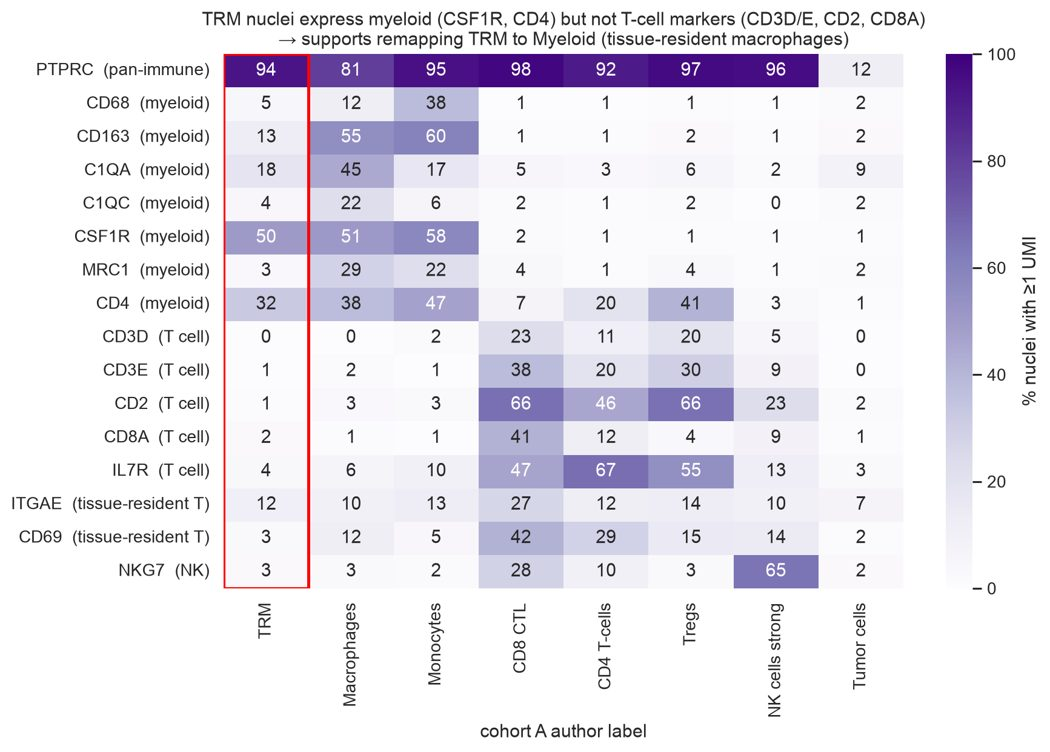

In [6]:
show(config.OUTPUTS_DIR / "step_1_output" / "07_TRM_marker_check.png", 700)

## 2 · QC and exploratory structure
Per-specimen, assay-aware flags. Flagged cells are removed in A and B; cohort C is excluded
(non-mitochondrial counts capped at ≤ 409 per cell).

In [7]:
q = table("stage2_qc_by_specimen")
q.groupby("cohort").apply(
    lambda d: pd.Series({"cells": d["cells"].sum(),
                         "removed_frac": 1 - (d["cells"] * d["pass_frac"]).sum() / d["cells"].sum(),
                         "median_pct_mt": d["median_pct_mt"].median()}),
    include_groups=False,
).round(3)

,cells,removed_frac,median_pct_mt
cohort,,,
A,141950.0,0.042,0.086
B,157881.0,0.009,1.668
C,29499.0,0.127,51.188


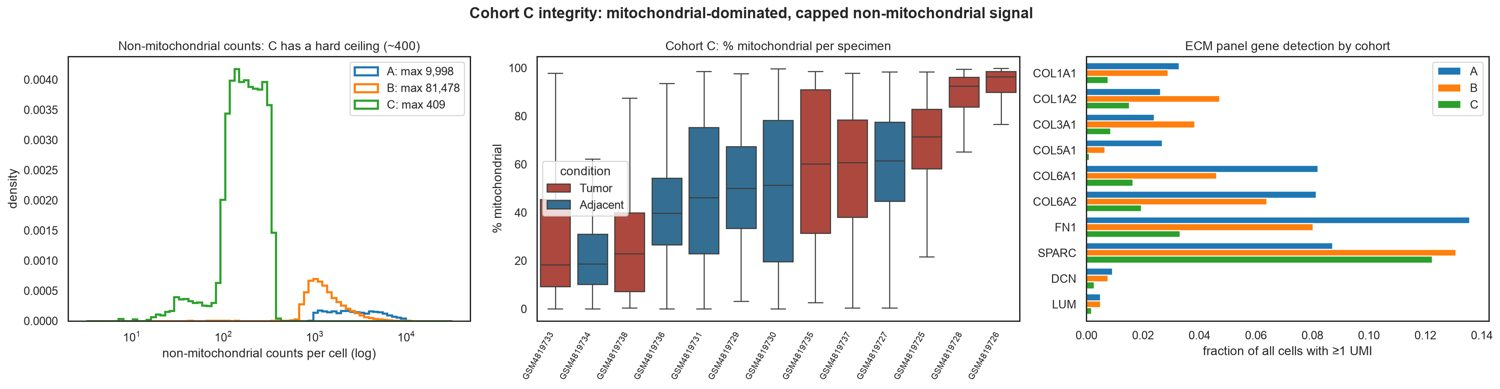

In [8]:
show(config.OUTPUTS_DIR / "step_2_output" / "08_cohortC_integrity.png")

In [9]:
table("stage2_pseudobulk_pca_r2_ALL").query("term == 'cohort'").head(3).round(2)

,PC,var_explained,term,R2
0,PC1,0.83,cohort,0.99
3,PC2,0.05,cohort,0.75
6,PC3,0.02,cohort,0.02


## 3 · Combining cohorts: baseline vs Harmony

In [10]:
table("stage3_integration_metrics").round(3)

,embedding,cells,cLISI_scaled,celltype_ASW,ARI,NMI,iLISI_scaled,batch_ASW
0,A_baseline,39632,1.0,0.625,0.100,0.496,NaN,NaN
1,AB_baseline,87489,1.0,0.624,0.291,0.637,0.000,0.485
2,AB_harmony,87489,1.0,0.649,0.392,0.662,0.003,0.807
3,AB_harmony_spec,87489,1.0,0.631,0.561,0.727,0.000,0.428


In [11]:
table("stage3_label_transfer").round(3)

,embedding,direction,accuracy,balanced_accuracy
0,AB_baseline,A->B,0.845,0.785
1,AB_baseline,B->A,0.659,0.655
2,AB_harmony,A->B,0.963,0.885
3,AB_harmony,B->A,0.869,0.880
4,AB_harmony_spec,A->B,0.947,0.807
5,AB_harmony_spec,B->A,0.304,0.546


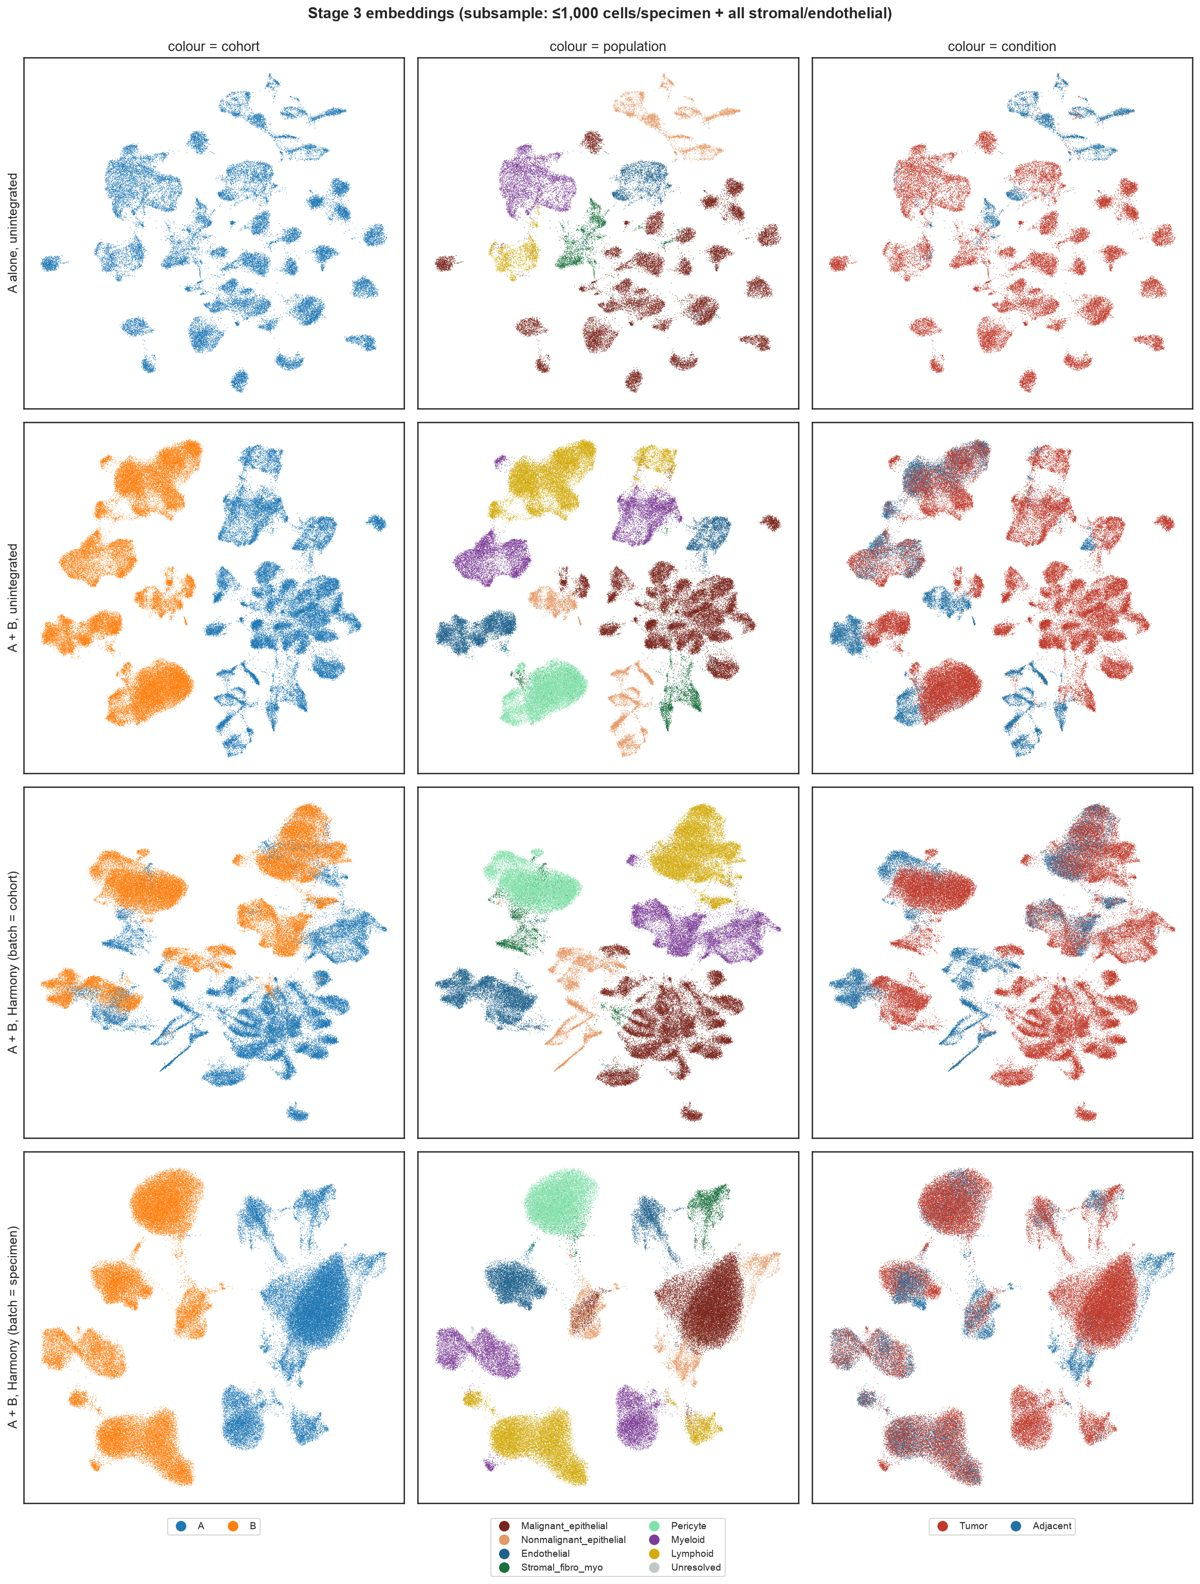

In [12]:
show(config.OUTPUTS_DIR / "step_3_output" / "01_umap_baseline_vs_harmony.png", 800)

## 4 · ECM program across populations; summary and focus population

In [13]:
med = table("stage4_ecm_median_logcpm").set_index(["cohort", "population"])
med.drop(index="ALL", level="population").round(1)

COL1A1  COL1A2  COL3A1  COL5A1  COL6A1  COL6A2  FN1  SPARC  DCN  LUM
cohort population                                                                                   
A      Endothelial                 2.2     1.8     3.6     2.5     3.7     4.8  7.3    7.8  0.0  0.0
       Lymphoid                    1.9     1.4     0.4     2.6     2.4     3.5  3.9    3.0  0.0  0.0
       Malignant_epithelial        2.3     1.6     1.3     1.6     4.1     4.6  4.0    4.1  0.4  0.1
       Myeloid                     1.5     1.4     1.5     1.3     2.7     3.1  6.1    3.4  0.0  0.0
       Nonmalignant_epithelial     3.1     1.3     1.6     2.5     5.8     4.4  3.7    3.8  0.2  0.0
       Stromal (fibro+mural)       6.6     7.6     6.8     6.7     6.3     7.5  9.1    7.2  3.1  0.7
       Stromal_fibro_myo           6.6     7.6     6.8     6.7     6.3     7.5  9.1    7.2  3.1  0.7
       Unresolved                  0.0     0.0     0.0     0.0     3.0     2.3  6.5    2.7  0.0  0.0
B      Endothelial                 1.6     2.6     5.6     1.6     4.5     5.0  8.6   10.4  0.0  0.0
       Lymphoid                    1.6     0.9     0.4     0.5     1.2     3.0  2.0    2.9  0.2  0.0
       Malignant_epithelial        3.3     3.7     1.9     0.6     4.1     4.1  4.7    5.3  0.0  0.0
       Myeloid                     0.9     0.7     0.7     0.0     1.2     0.6  4.2    2.6  0.6  0.3
       Nonmalignant_epithelial     2.3     2.3     2.0     1.0     6.4     3.8  1.9    5.3  4.2  0.0
       Pericyte                    6.5     8.1     7.3     4.0     7.4     8.6  8.1    9.8  3.5  0.0
       Stromal (fibro+mural)       6.6     8.2     7.6     4.3     7.4     8.6  8.1    9.8  6.1  4.9
       Stromal_fibro_myo           9.7    10.3     9.4     6.7     8.1     9.3  9.8   10.7  9.0  8.8
       Unresolved                  6.6     7.6     7.2     4.0     6.5     7.6  8.0    9.5  5.4  3.2

In [14]:
table("stage4_focus_coverage").query("population != 'ALL'")

,cohort,population,paired_donors_ge10,paired_donors_ge20,paired_donors_ge50
1,A,Endothelial,3,2,0
2,A,Lymphoid,2,2,2
3,A,Malignant_epithelial,0,0,0
4,A,Myeloid,3,3,3
5,A,Nonmalignant_epithelial,1,1,1
6,A,Stromal (fibro+mural),3,2,1
7,A,Stromal_fibro_myo,3,2,1
8,A,Unresolved,1,1,0
10,B,Endothelial,9,8,8
11,B,Lymphoid,9,9,9


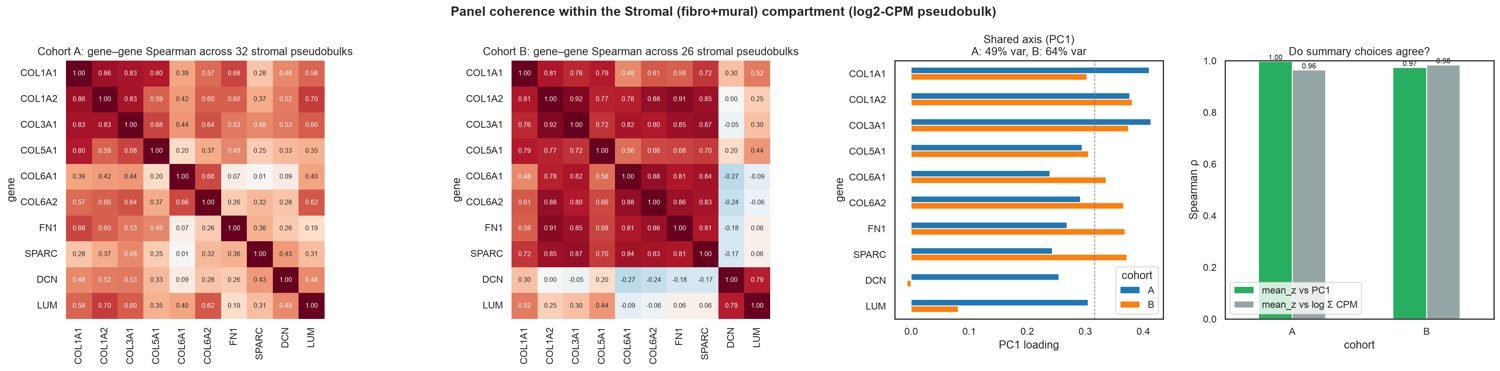

In [15]:
show(config.OUTPUTS_DIR / "step_4_output" / "03_panel_coherence.png")

## 5 · Tumor vs adjacent in the fibroblast + mural compartment
Pseudobulk log2-CPM per specimen; donors are replicates (tumor regions averaged; paired within
donor); exact sign-flip p; random-effects meta-analysis across cohorts.

In [16]:
e = table("stage5_effects")
cols = ["analysis", "cohort", "feature", "n_donors", "mean", "ci_low", "ci_high", "n_up",
        "p_signflip", "q_BH", "random", "random_low", "random_high", "I2"]
e[e["feature"].isin(["panel_z", "panel_z_noDCN_LUM"])][cols].round(3)

,analysis,cohort,feature,n_donors,mean,ci_low,ci_high,n_up,p_signflip,q_BH,random,random_low,random_high,I2
10,"primary: stroma (fibro+mural), >=10 cells, reg...",A,panel_z,3.0,0.021,-1.771,1.813,1.0,1.000,NaN,NaN,NaN,NaN,NaN
11,"primary: stroma (fibro+mural), >=10 cells, reg...",A,panel_z_noDCN_LUM,3.0,0.219,-0.968,1.406,1.0,1.000,NaN,NaN,NaN,NaN,NaN
23,"primary: stroma (fibro+mural), >=10 cells, reg...",B,panel_z,9.0,1.042,0.627,1.457,9.0,0.004,NaN,NaN,NaN,NaN,NaN
24,"primary: stroma (fibro+mural), >=10 cells, reg...",B,panel_z_noDCN_LUM,9.0,1.411,0.962,1.861,9.0,0.004,NaN,NaN,NaN,NaN,NaN
36,"primary: stroma (fibro+mural), >=10 cells, reg...",A+B,panel_z,12.0,NaN,NaN,NaN,10.0,0.003,NaN,0.601,-0.391,1.592,0.803
37,"primary: stroma (fibro+mural), >=10 cells, reg...",A+B,panel_z_noDCN_LUM,12.0,NaN,NaN,NaN,10.0,0.002,NaN,0.831,-0.337,1.999,0.920
49,sensitivity: >=20 cells,A,panel_z,2.0,0.115,-7.990,8.221,1.0,1.000,NaN,NaN,NaN,NaN,NaN
50,sensitivity: >=20 cells,A,panel_z_noDCN_LUM,2.0,0.372,-3.981,4.726,2.0,0.500,NaN,NaN,NaN,NaN,NaN
62,sensitivity: >=20 cells,B,panel_z,9.0,1.042,0.627,1.457,9.0,0.004,NaN,NaN,NaN,NaN,NaN
63,sensitivity: >=20 cells,B,panel_z_noDCN_LUM,9.0,1.411,0.962,1.861,9.0,0.004,NaN,NaN,NaN,NaN,NaN


In [17]:
e[e["analysis"].str.startswith("primary") & e["cohort"].eq("B")][
    ["feature", "mean", "ci_low", "ci_high", "n_up", "q_BH"]
].round(3)

,feature,mean,ci_low,ci_high,n_up,q_BH
13,COL1A1,1.309,0.177,2.442,7.0,0.028
14,COL1A2,2.647,1.782,3.512,9.0,0.010
15,COL3A1,2.573,1.508,3.639,9.0,0.010
16,COL5A1,0.933,-0.111,1.977,8.0,0.088
17,COL6A1,1.037,0.392,1.682,8.0,0.026
18,COL6A2,1.662,0.956,2.369,8.0,0.016
19,FN1,2.065,1.374,2.756,9.0,0.010
20,SPARC,1.743,1.174,2.313,9.0,0.010
21,DCN,-1.673,-4.136,0.789,3.0,0.169
22,LUM,-0.717,-4.064,2.631,4.0,0.641


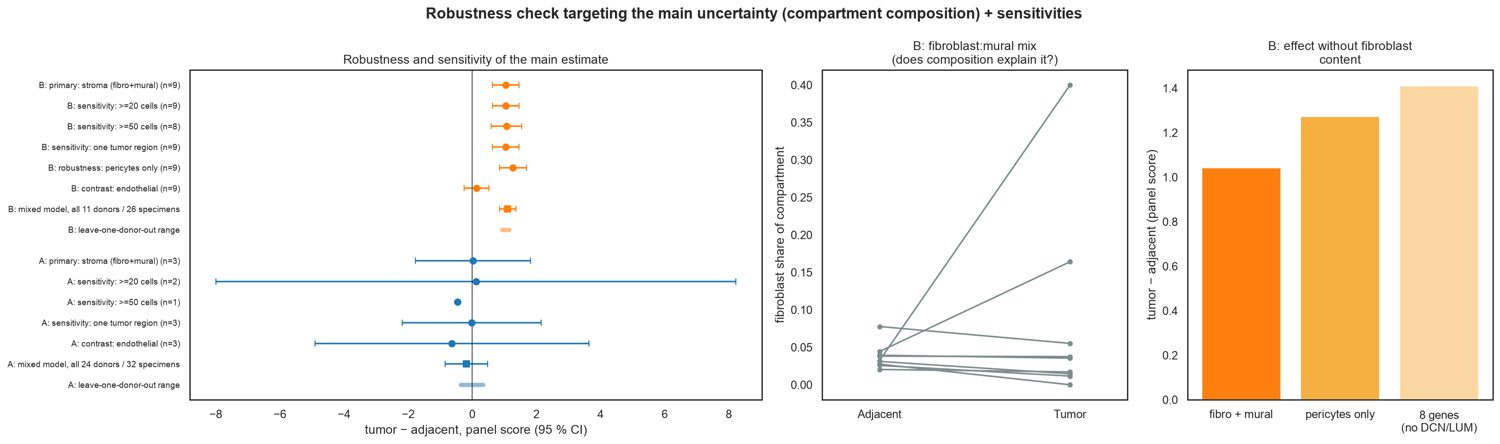

In [18]:
show(config.OUTPUTS_DIR / "step_5_output" / "03_robustness.png")

## 6 · Linked modalities

In [19]:
v = table("stage6_crosswalk_validation")
v[["linked", "primary", "in_RNA_file", "in_protein_file", "protein_aliquot_matches_anchor",
   "snRNA_parent_matches_protein_parent"]].sum()

linked                                 29
primary                                27
in_RNA_file                            29
in_protein_file                        29
protein_aliquot_matches_anchor         29
snRNA_parent_matches_protein_parent    27
dtype: int64

In [20]:
table("stage6_matched_donors")

,donor_id,primary_pair
0,C3L-00079,True
1,C3L-00088,True
2,C3N-00242,False
3,C3N-01200,True


In [21]:
e6 = table("stage6_effects")
e6[e6["feature"] == "panel_z"][["scope", "assay", "n_donors", "mean", "ci_low", "ci_high", "n_up",
                                "p_signflip"]].round(3)

,scope,assay,n_donors,mean,ci_low,ci_high,n_up,p_signflip
10,"matched subset (3 donors, primary links)",snRNA stroma,3,-0.219,-1.523,1.086,1,0.500
21,"matched subset (3 donors, primary links)",snRNA whole specimen,3,-0.139,-2.634,2.357,1,1.000
32,"matched subset (3 donors, primary links)",bulk RNA,3,0.481,-1.841,2.803,2,0.500
43,"matched subset (3 donors, primary links)",bulk protein,3,0.259,-0.728,1.245,2,0.500
54,matched + C3N-00242 (4 donors),snRNA stroma,3,-0.219,-1.523,1.086,1,0.500
65,matched + C3N-00242 (4 donors),snRNA whole specimen,4,-0.716,-2.970,1.538,1,0.500
76,matched + C3N-00242 (4 donors),bulk RNA,4,0.071,-1.712,1.853,2,0.875
87,matched + C3N-00242 (4 donors),bulk protein,4,-0.167,-1.617,1.283,2,0.875
98,"full bulk cohort (context, not matched)",bulk RNA (all paired donors),72,0.519,0.309,0.729,54,0.000
109,"full bulk cohort (context, not matched)",bulk protein (all paired donors),80,0.680,0.493,0.867,67,0.000


In [22]:
table("stage6_composition_corr").round(3)

,marker_set,spearman_rho,p,spearman_rho_noDCN_LUM,p_noDCN_LUM,n_donors,mean_marker_change_z,frac_donors_marker_down
0,mural,0.618,0.000,0.618,0.000,72,0.559,0.292
1,fibroblast,0.766,0.000,0.682,0.000,72,-1.544,0.972
2,endothelial,0.261,0.027,0.288,0.014,72,1.631,0.028


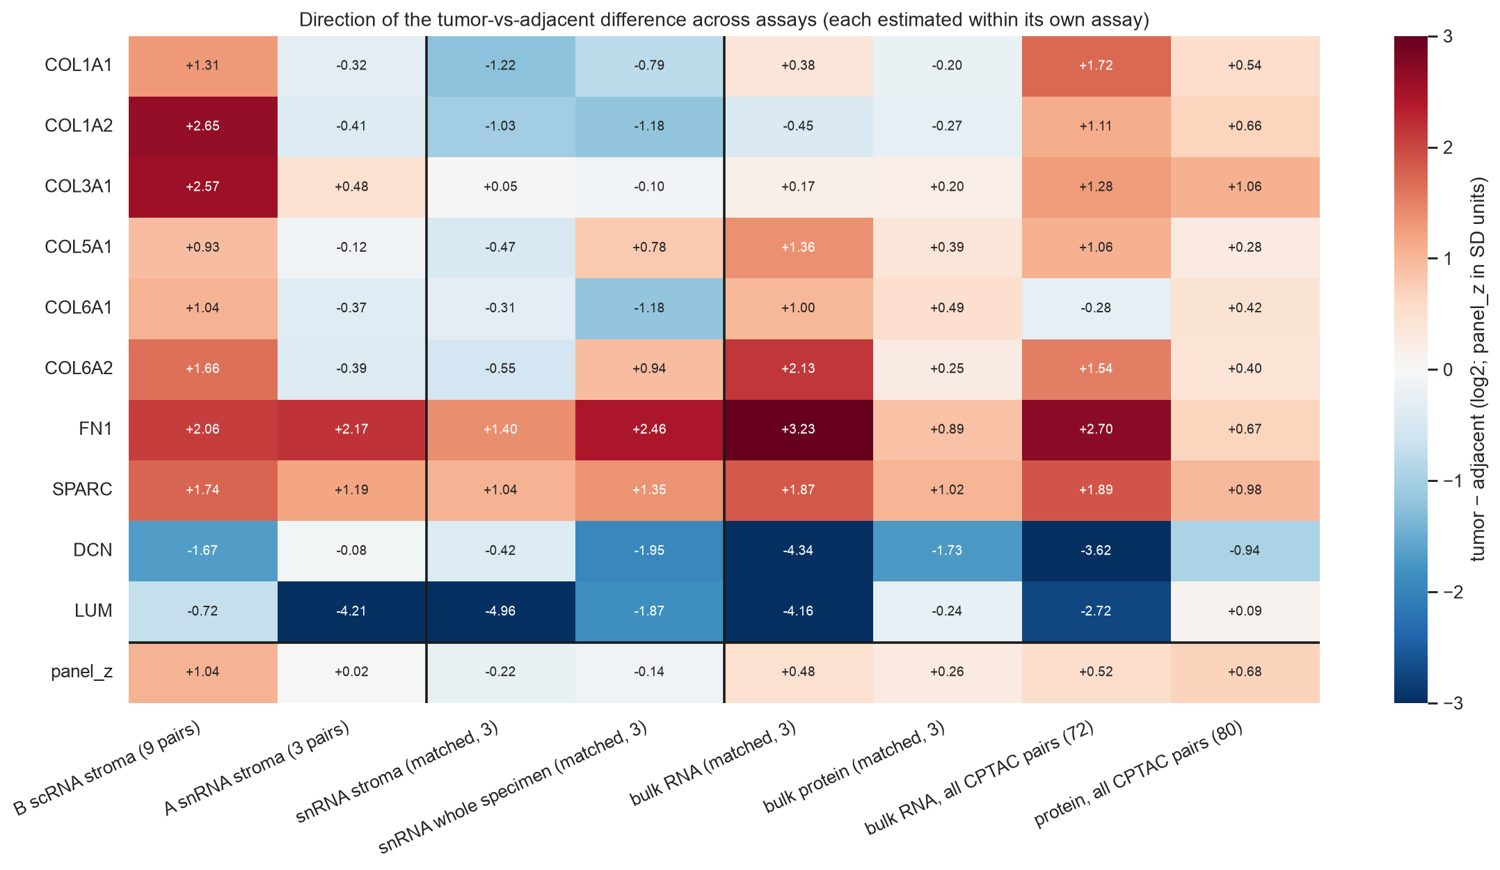

In [23]:
show(config.OUTPUTS_DIR / "step_6_output" / "02_cross_assay_agreement.png")

## Report figures
The three report figures (one per assignment section) are built by `opengo figures report`.

**figure1_qc_integration.png**

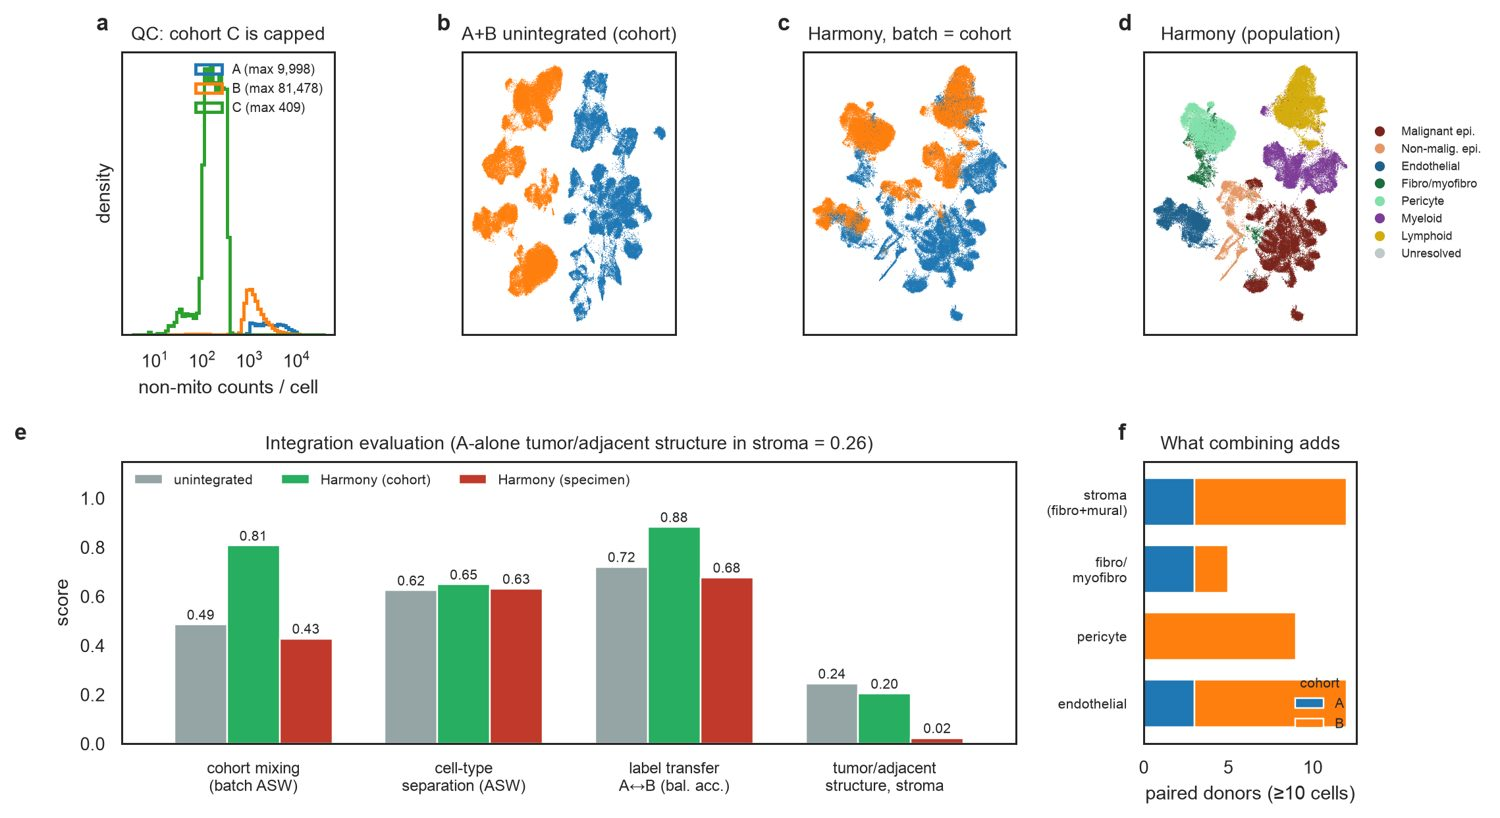

**figure2_ecm_program.png**

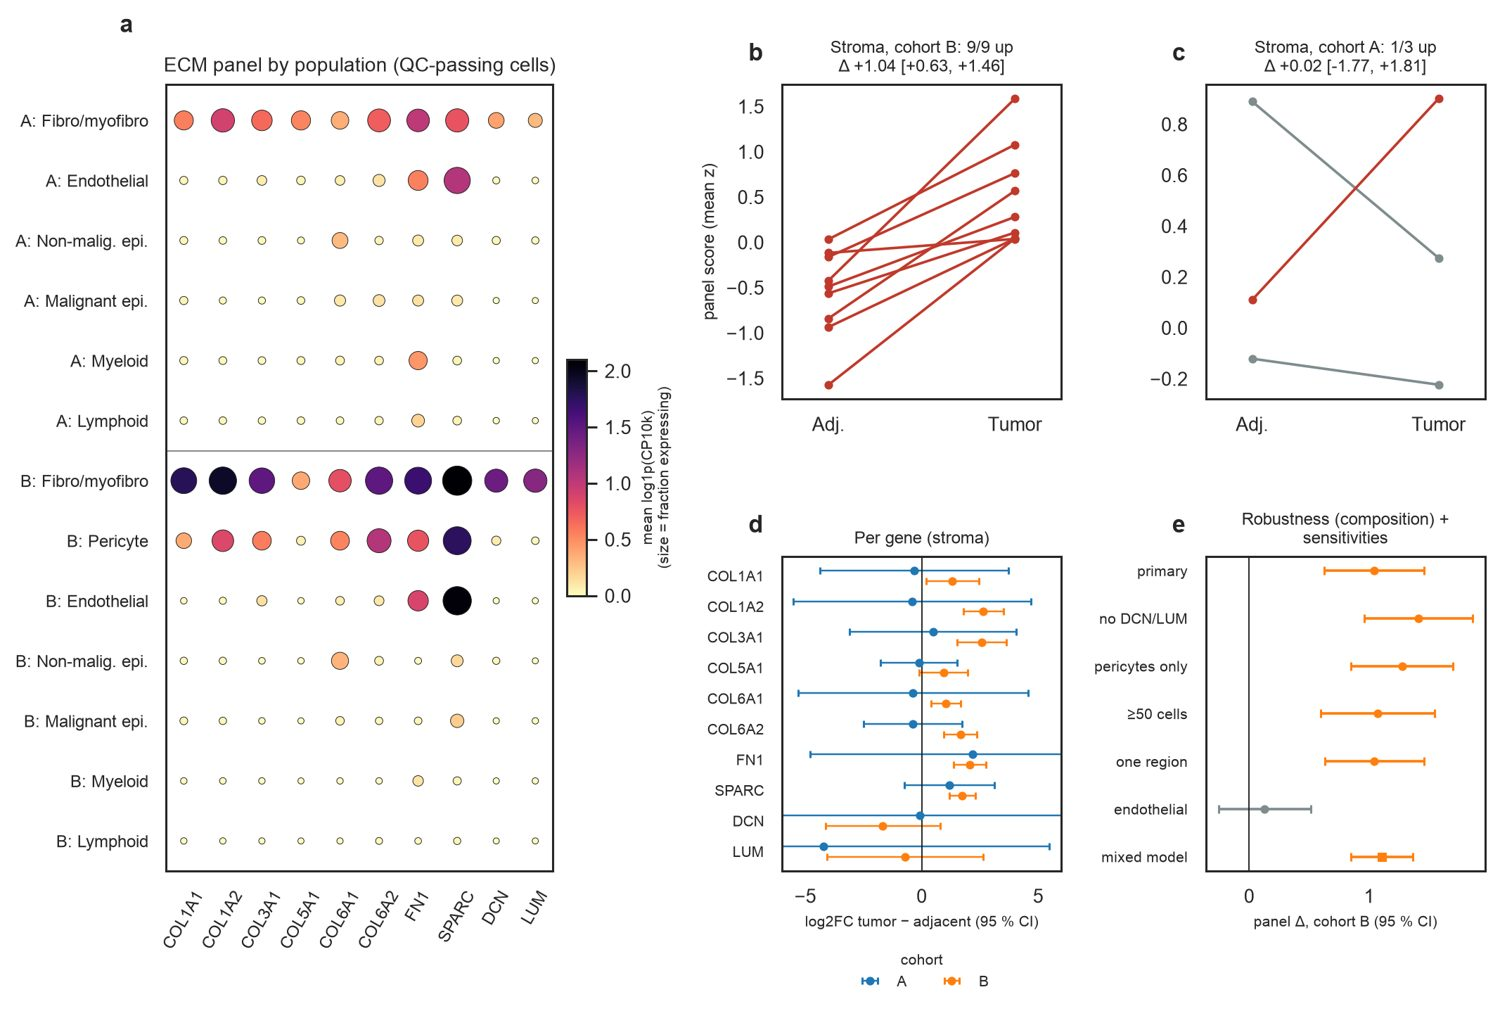

**figure3_multimodal.png**

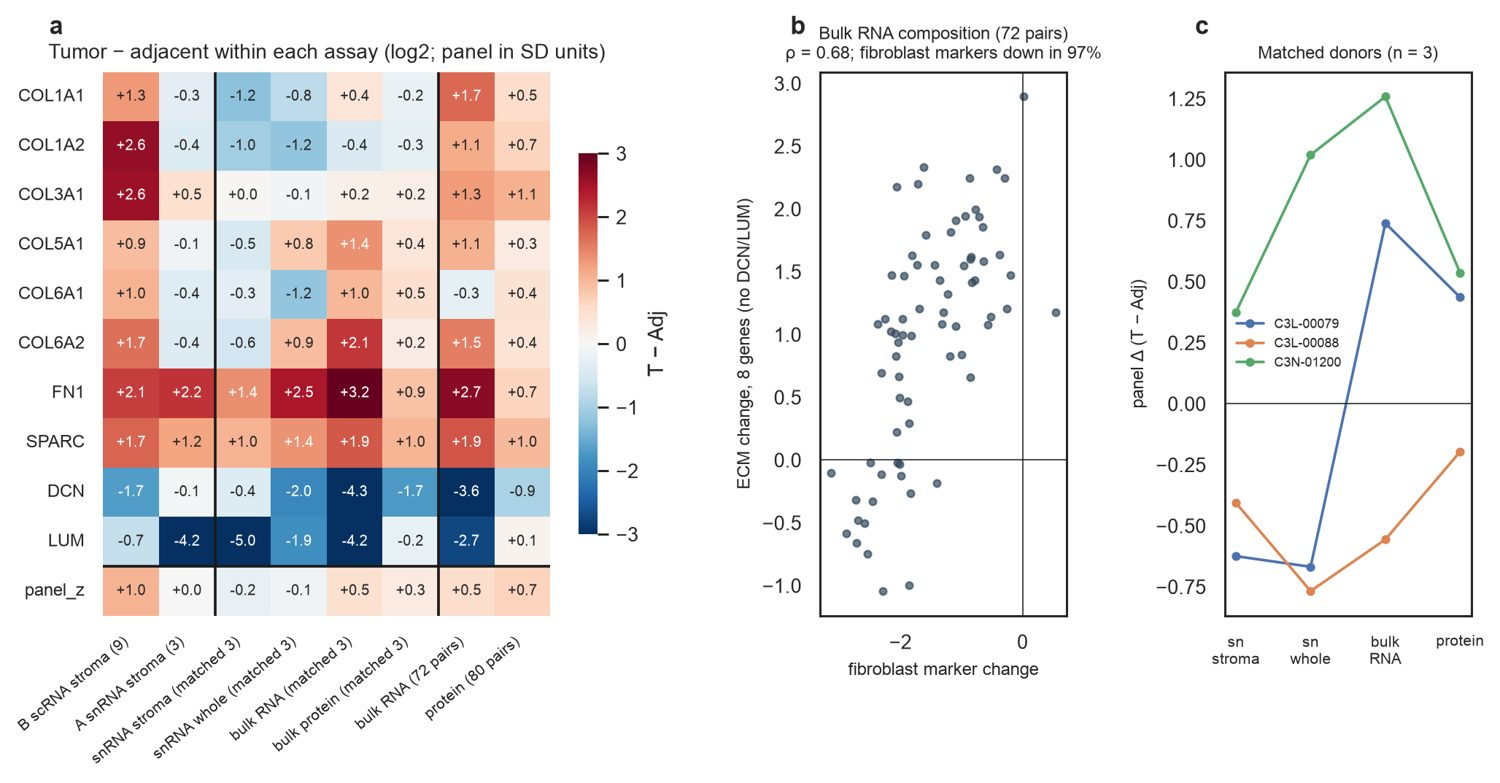

In [24]:
for f in sorted((config.PROJECT_ROOT / "report" / "figures").glob("figure*.png")):
    display(Markdown(f"**{f.name}**"))
    show(f)